# user

In [1]:
VERSION = "0.0.3"
ASSOC = False
PIXEL_SCALE = 0.1

# lib

In [2]:
from pathlib import Path
import numpy
import tensorflow_datasets as tfds
from pandas import read_csv, concat, interval_range, cut, DataFrame, Series
from tqdm import tqdm
from plots import (
    image_fitting,
    histos,
    residuals,
    case_result_param,
    vignettes,
    DIRS,
    comparaison,
    get_match,
    result_e,
    compute_by_bin,
    DIR_DATASETS,
    results_by_image,
    load_truth,
    filtering,
    TO_DROP,
    compute_ellips,
    result_by_bin,
    compute_res,
    decode_flags,
    compute_flags,
)
from matplotlib import pyplot


DATASET_DIR_ORIGIN = DIRS["pisco_euclid"] / VERSION
DATASET_DIR = DIRS["pisco_euclid_se"] / VERSION
RESULTS_DIR = Path("/net/GECO/pisco/PIX2SHEAR/RESULTS_SEXTRACTOR") / f"{VERSION}++"
if ASSOC:
    RESULTS_DIR = RESULTS_DIR.parent / f"{RESULTS_DIR.name}_assoc"
CATALOG_DIR = RESULTS_DIR / "CATALOG"
IMAGES_DIR = RESULTS_DIR / "IMAGES"
PLOTS_DIR = RESULTS_DIR / "PLOTS"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

2025-06-25 11:13:59.086750: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-06-25 11:13:59.127084: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


# inference

In [3]:
PRED_FILES = sorted(list((CATALOG_DIR).glob("*_simu.csv")))
TRUE_FILES = sorted(list((DATASET_DIR).glob("*_true_galaxies_params.csv")))
detections, pred_gal, pred_gal_slice, true_gal_slice = [[] for _ in range(4)]
pred_avg_e1, pred_avg_e2, pred_avg_e1_err, pred_avg_e2_err = [[] for _ in range(4)]
for i, (res_file, true_file) in enumerate(tqdm(zip(PRED_FILES, TRUE_FILES), total=len(PRED_FILES))):
    # load results
    df_pred = read_csv(res_file).sort_values("x_model")
    df_pred = df_pred.dropna(subset=["e2_model_err", "e1_model_err"])
    df_pred = df_pred[(df_pred["e2_model_err"] <= 1) & (df_pred["e1_model_err"] <= 1)]

    detections.append(df_pred.shape[0])
    df_true = read_csv(true_file).sort_values("x")

    # slices
    temp_pred, temp_truth = get_match(df_pred, df_true, radius=2)
    temp_pred["image"] = i
    temp_truth["image"] = i
    pred_gal_slice.append(temp_pred)
    true_gal_slice.append(temp_truth)

    # predictions galaxies
    df_pred["image"] = i
    pred_gal.append(df_pred)

    # image means
    mu_e1, err_e1 = compute_ellips(df_pred["e1_model"], df_pred["e1_model_err"])
    mu_e2, err_e2 = compute_ellips(df_pred["e2_model"], df_pred["e2_model_err"])
    pred_avg_e1.append(mu_e1)
    pred_avg_e2.append(mu_e2)
    pred_avg_e1_err.append(err_e1)
    pred_avg_e2_err.append(err_e2)

# results
detections = numpy.array(detections)
pred_gal = concat(pred_gal, ignore_index=True)
pred_avg = DataFrame(
    {
        "avg_obs_e1": numpy.array(pred_avg_e1),
        "avg_obs_e2": numpy.array(pred_avg_e2),
        "avg_obs_e1_err": numpy.array(pred_avg_e1_err),
        "avg_obs_e2_err": numpy.array(pred_avg_e2_err),
    }
)
pred_gal_slice = concat(pred_gal_slice, ignore_index=True)
true_gal_slice = concat(true_gal_slice, ignore_index=True)
pred_gal.drop(TO_DROP, axis=1, inplace=True)
pred_gal_slice.drop(TO_DROP, axis=1, inplace=True)

del df_pred, df_true, mu_e1, mu_e2, err_e1, err_e2, PRED_FILES, TRUE_FILES, pred_avg_e1, pred_avg_e2
del res_file, true_file, temp_pred, temp_truth, pred_avg_e2_err, pred_avg_e1_err, ASSOC, DIRS

100%|██████████| 20000/20000 [11:59<00:00, 27.80it/s] 


# load truth

In [4]:
dataset, _ = tfds.load(
    f"{'pisco_euclid'}:{VERSION}",
    split=f"{'dataset'}[:{100}%]",
    data_dir=DIR_DATASETS,
    with_info=True,
    shuffle_files=False,  # no True to match the csv files
)
print(dataset.element_spec.keys())

true_avg, true_gal = load_truth(dataset)

del VERSION, dataset

dict_keys(['avg_g', 'avg_int_e', 'avg_obs_e', 'gal_params', 'image', 'keys'])


100%|██████████| 20000/20000 [00:28<00:00, 709.22it/s] 


# post process

In [5]:
top = 0.06
mask = (true_avg["avg_g1"].abs() <= top) & (true_avg["avg_g2"].abs() <= top)
pred_avg_mask, true_avg_mask, detections_mask, pred_gal_mask, true_gal_mask = filtering(
    pred_avg, true_avg, detections, pred_gal, true_gal, mask
)

mask_snc_1 = true_avg["snc"] == 1
pred_avg_snc_1, true_avg_snc_1, detections_snc_1, pred_gal_snc_1, true_gal_snc_1 = filtering(
    pred_avg, true_avg, detections, pred_gal, true_gal, mask_snc_1
)

mask_snc_12 = true_avg["snc"].isin([1, 2])
pred_avg_snc_12, true_avg_snc_12, detections_snc_12, pred_gal_snc_12, true_gal_snc_12 = filtering(
    pred_avg, true_avg, detections, pred_gal, true_gal, mask_snc_12
)

print(NB_GAL_TOTAL := true_gal.shape[0])
print(NB_GAL_PRED := pred_gal.shape[0])
del mask, mask_snc_1, mask_snc_12, top

200000
182932


# histo

[]


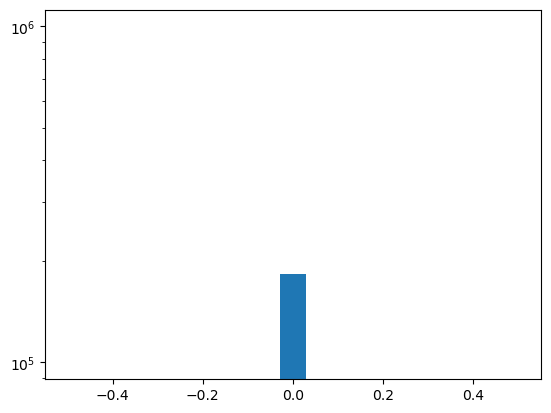

In [6]:
nonzero_flags = compute_flags(pred_gal_mask)
print(nonzero_flags)

In [7]:
if len(nonzero_flags) != 0:
    for cas in nonzero_flags:
        print(decode_flags(cas))

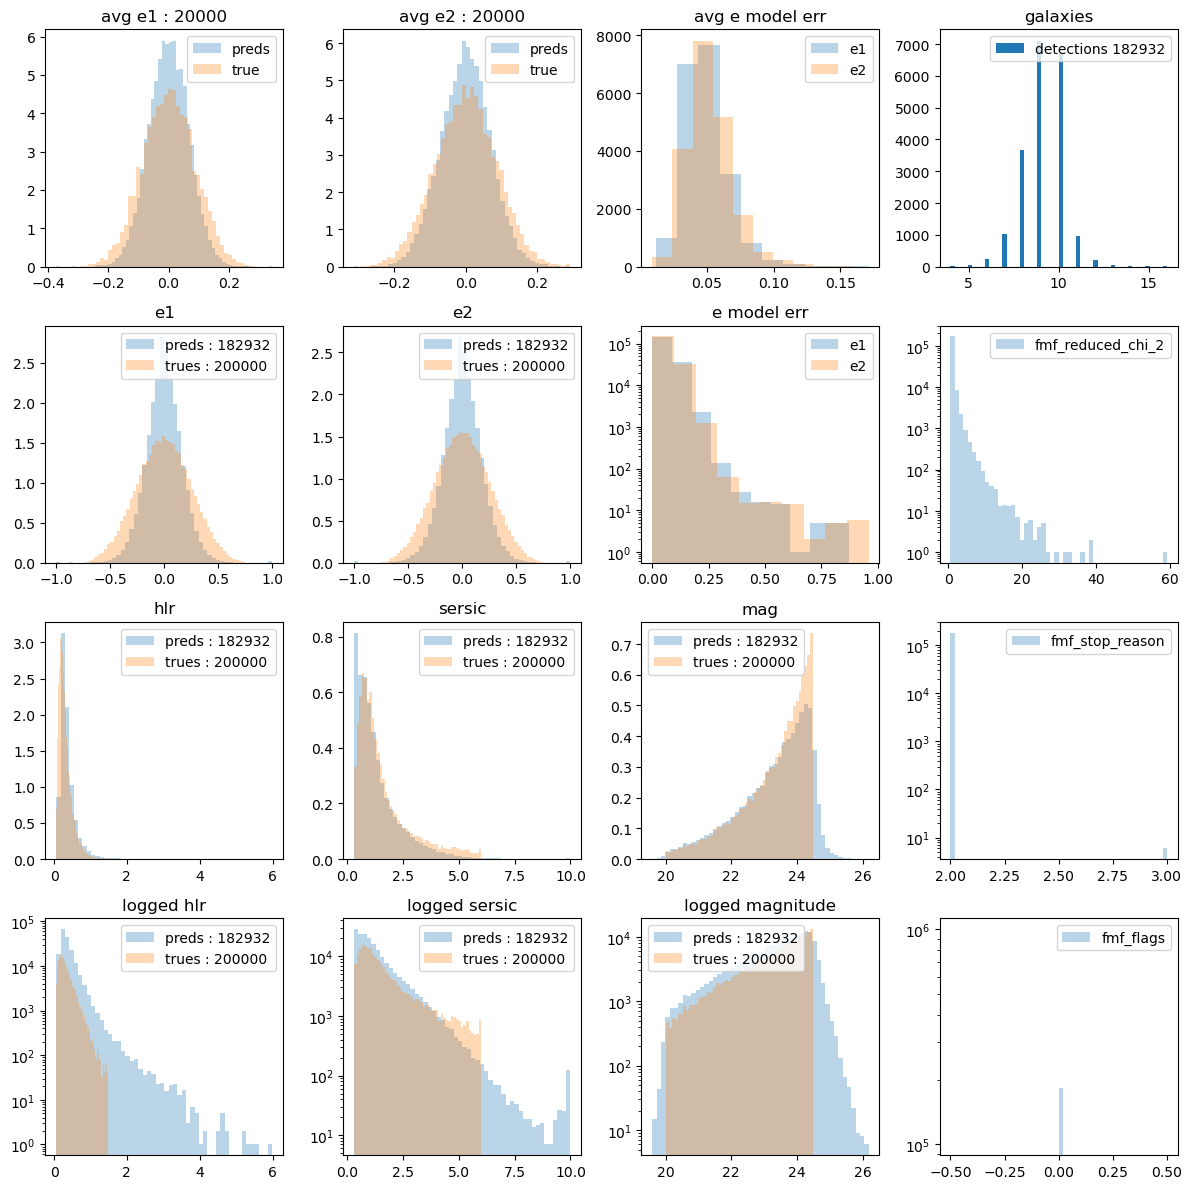

In [8]:
histos(
    detections_mask,
    pred_gal_mask,
    true_gal_mask,
    pred_avg_mask,
    true_avg_mask,
    PLOTS_DIR,
    PIXEL_SCALE,
    bins=50,
)

# results

In [9]:
# results_by_image(PLOTS_DIR, pred_avg_snc_1, true_avg_snc_1, alpha=0.5, name="pred_snc1")
# results_by_image(PLOTS_DIR, pred_avg_snc_12, true_avg_snc_12, alpha=0.5, name="pred_snc12")

# df_1, df_2 = compute_by_bin(true_avg_snc_1, pred_gal_snc_1)
# result_by_bin(PLOTS_DIR, df_1, df_2, style="true_g", name="pred_snc1")
# df_1, df_2 = compute_by_bin(true_avg_snc_12, pred_gal_snc_12)
# result_by_bin(PLOTS_DIR, df_1, df_2, style="true_g", name="pred_snc1")

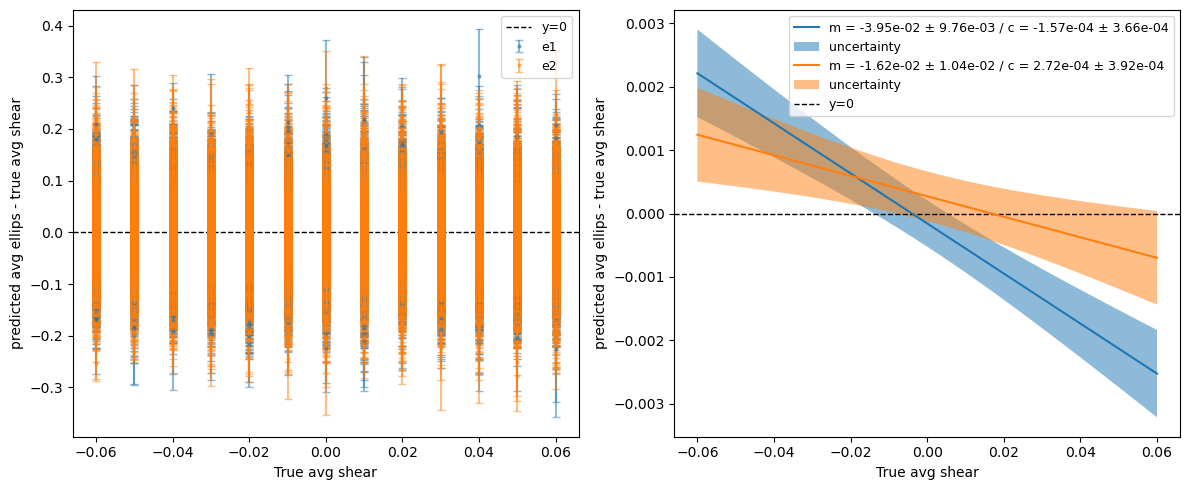

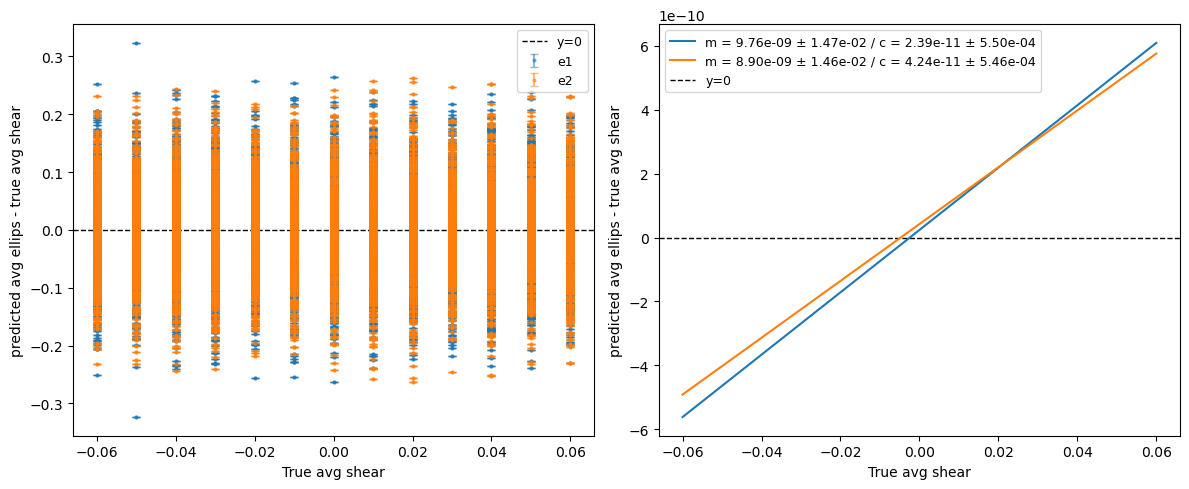

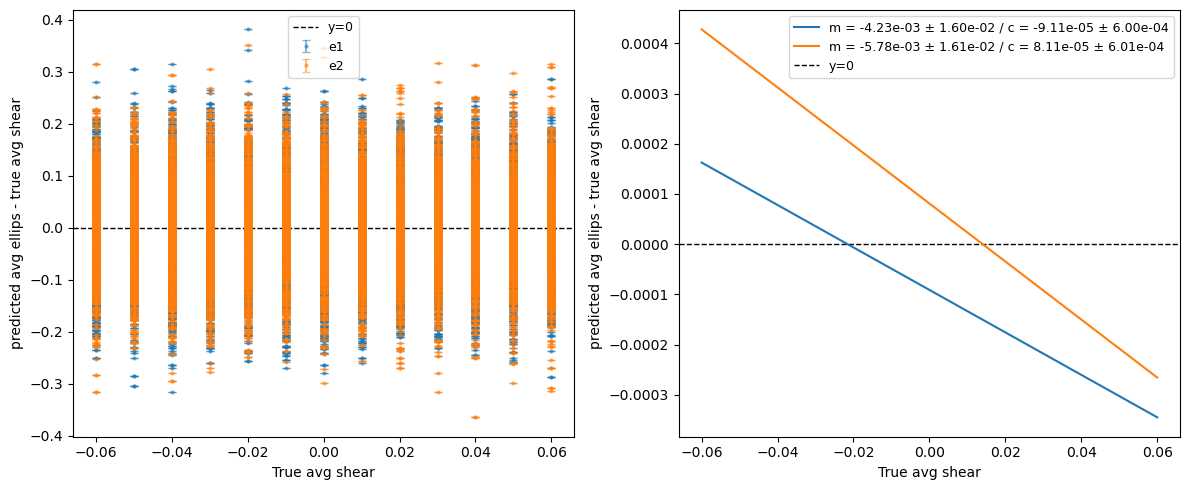

In [10]:
results_by_image(PLOTS_DIR, pred_avg_mask, true_avg_mask, alpha=0.5, name="pred")

results_by_image(PLOTS_DIR, true_avg_mask, true_avg_mask, alpha=0.5, name="theory")

true_gal_slice_avg = true_gal_slice.groupby("image", as_index=False).agg(
    avg_obs_e1=("obs_e1", "mean"), avg_obs_e2=("obs_e2", "mean")
)
true_gal_slice_avg.rename(columns={"obs_e1": "avg_obs_e1", "obs_e2": "avg_obs_e2"}, inplace=True)
results_by_image(PLOTS_DIR, true_gal_slice_avg, true_avg_mask, alpha=0.5, name="pred_truth")

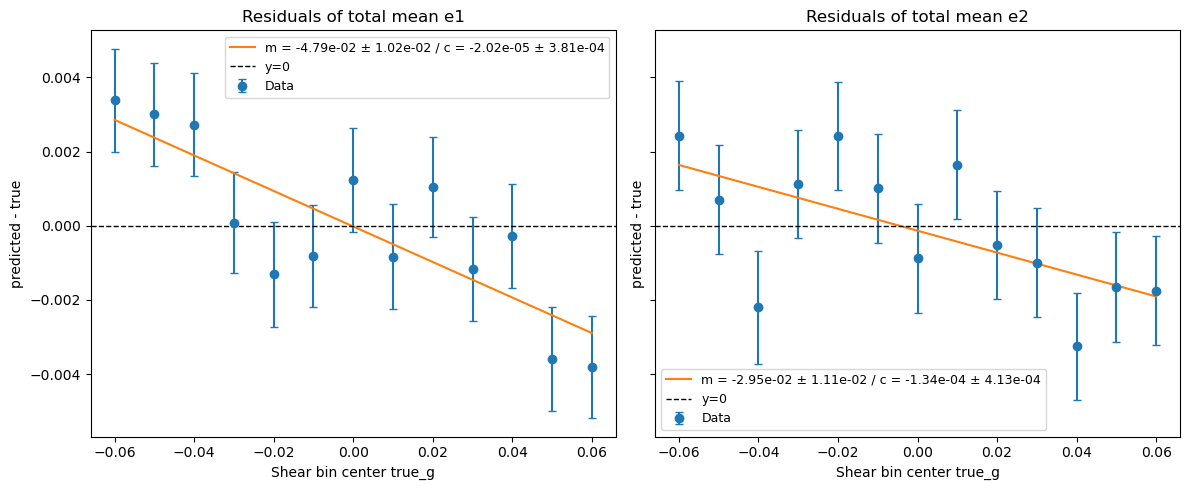

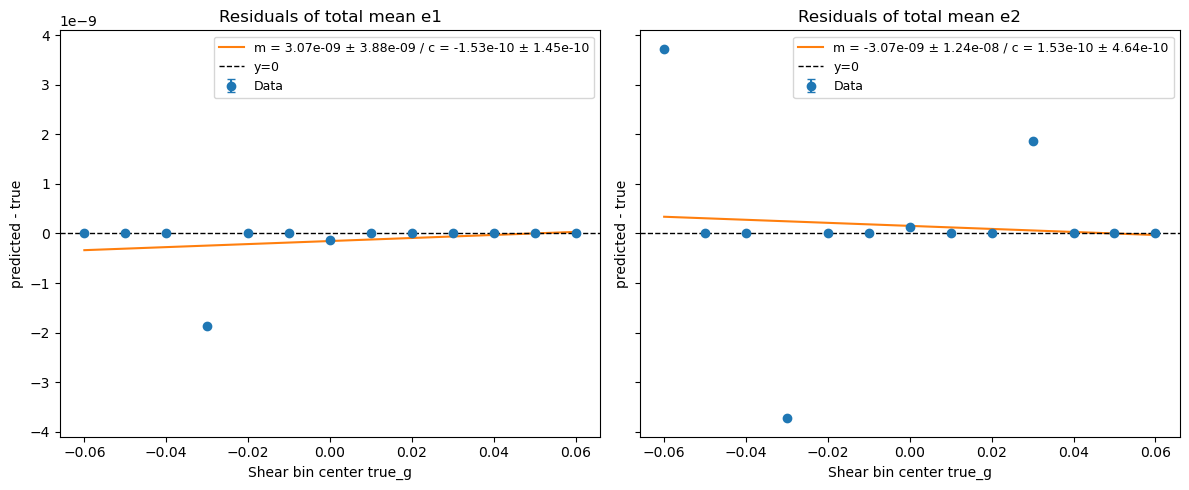

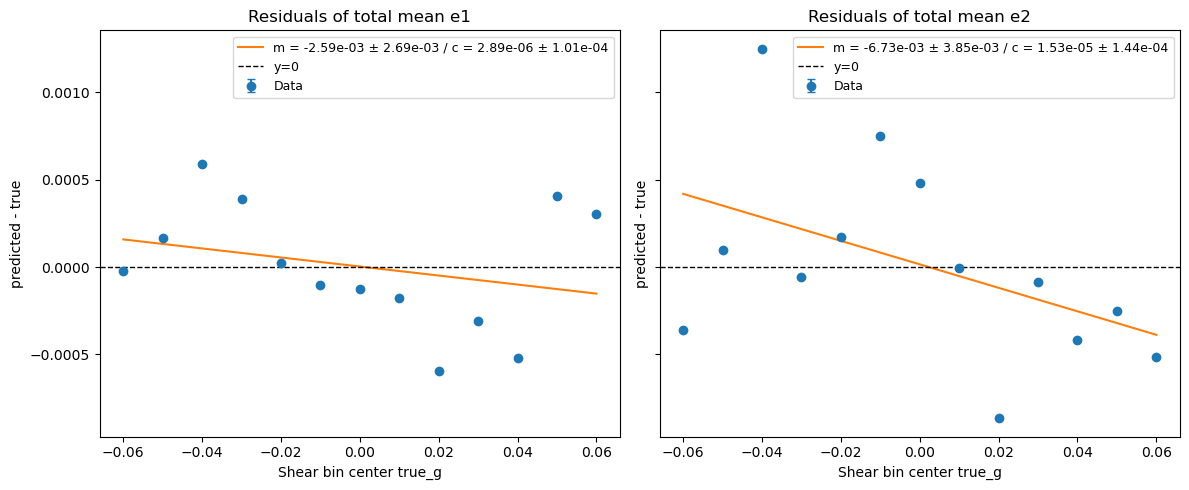

In [11]:
df_1, df_2 = compute_by_bin(true_avg_mask, pred_gal_mask)
result_by_bin(PLOTS_DIR, df_1, df_2, style="true_g", name="pred")

true_gal.rename(columns={"obs_e1": "e1_model", "obs_e2": "e2_model"}, inplace=True)
true_gal["e1_model_err"] = 0
true_gal["e2_model_err"] = 0
df_1, df_2 = compute_by_bin(true_avg_mask, true_gal)
result_by_bin(PLOTS_DIR, df_1, df_2, style="true_g", name="theory")

true_gal_slice.rename(columns={"obs_e1": "e1_model", "obs_e2": "e2_model"}, inplace=True)
true_gal_slice["e1_model_err"] = 0
true_gal_slice["e2_model_err"] = 0
df_1, df_2 = compute_by_bin(true_avg_mask, true_gal_slice)
result_by_bin(PLOTS_DIR, df_1, df_2, style="true_g", name="pred_truth")

# results by images

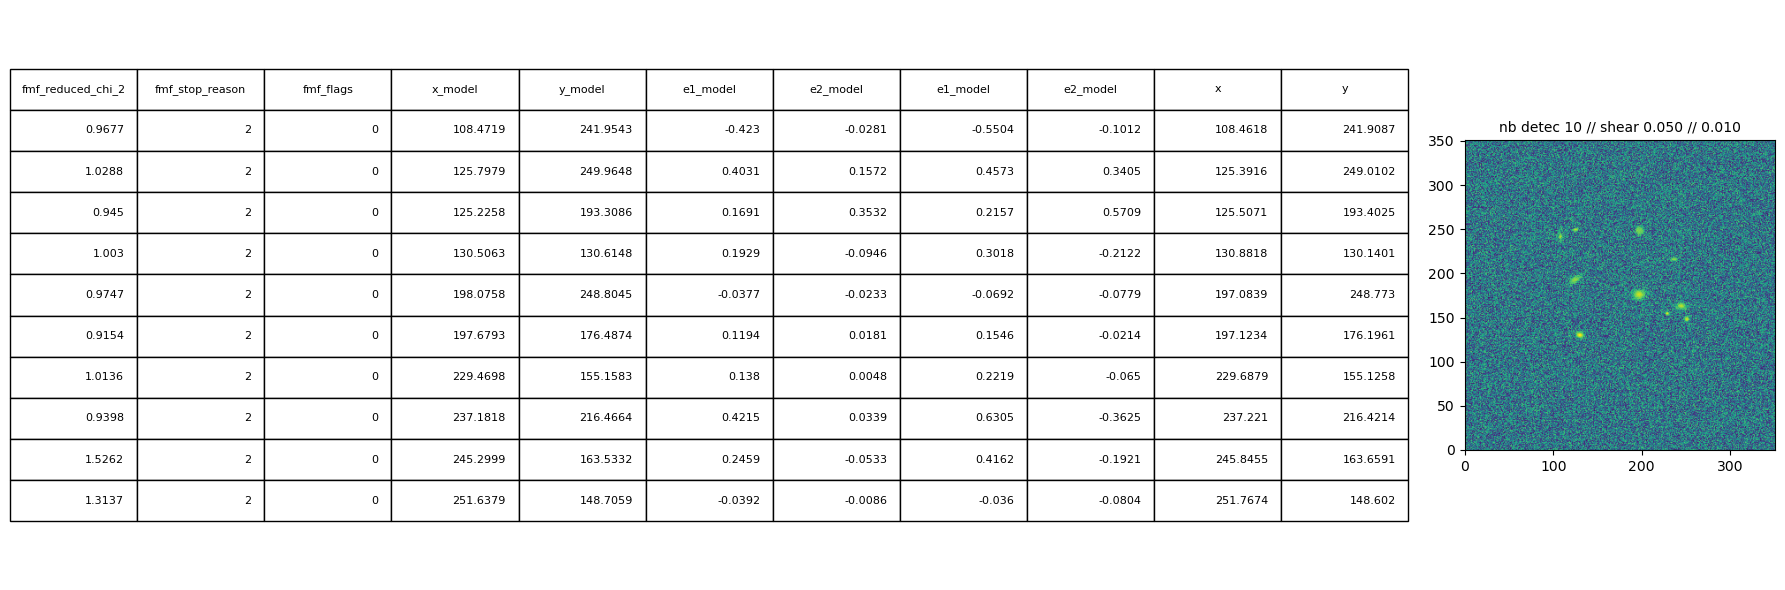

In [12]:
CHOICE = 0

CHOICE_IMAGE = int(numpy.unique(pred_gal_slice["image"])[CHOICE])
example_preds = pred_gal_slice[pred_gal_slice["image"] == CHOICE_IMAGE].reset_index(drop=True)
example_true = true_gal_slice[true_gal_slice["image"] == CHOICE_IMAGE].reset_index(drop=True)
comparaison(
    DATASET_DIR / f"{CHOICE_IMAGE:06d}_simu",
    example_preds[
        [
            "fmf_reduced_chi_2",
            "fmf_stop_reason",
            "fmf_flags",
            "x_model",
            "y_model",
            "e1_model",
            "e2_model",
        ]
    ],
    example_true[["e1_model", "e2_model", "x", "y"]].sort_values("x"),
    detections[CHOICE],
    true_avg["avg_g1"][CHOICE_IMAGE],
    true_avg["avg_g2"][CHOICE_IMAGE],
    PLOTS_DIR,
)

In [13]:
df, all_pixels = compute_res(IMAGES_DIR)

100%|██████████| 20000/20000 [10:31<00:00, 31.69it/s]


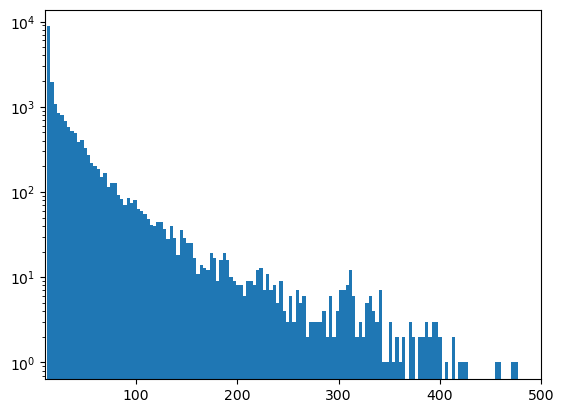

In [14]:
pyplot.hist(all_pixels, bins=200, log=True)
pyplot.xlim(10, 500)
pyplot.show()

In [15]:
mask_res = all_pixels <= 14
print(mask_res.sum())
mask_res = Series(mask_res, name="res")
pred_avg_mask_res, true_avg_mask_res, detections_mask_res, pred_gal_mask_res, true_gal_mask_res = (
    filtering(pred_avg, true_avg, detections, pred_gal, true_gal, mask_res)
)

5477


In [16]:
pred_avg.shape

(20000, 4)

In [17]:
pred_avg_mask_res.shape

(5477, 4)

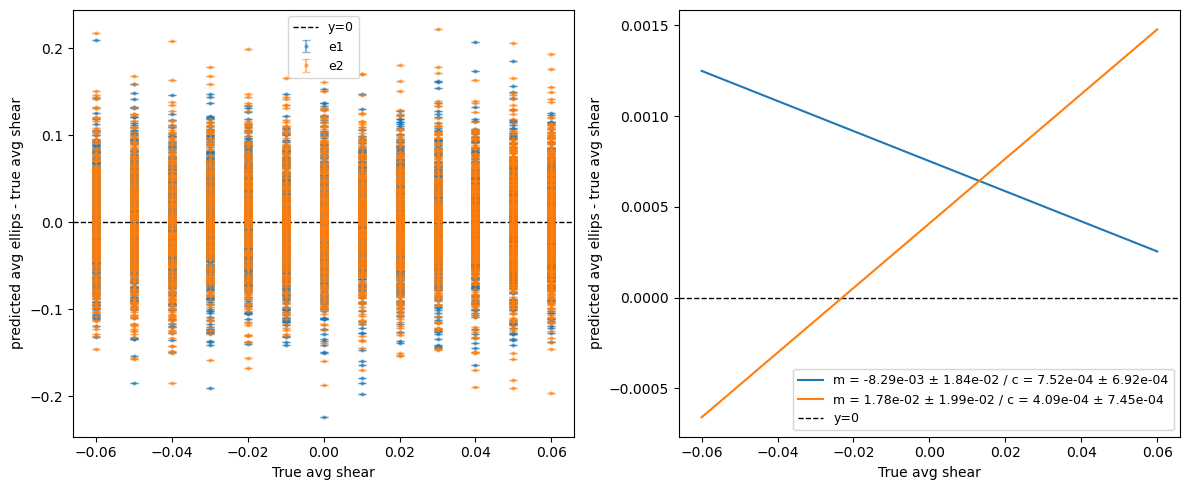

In [18]:
results_by_image(PLOTS_DIR, pred_avg_mask_res, true_avg_mask_res, alpha=0.5, name="res")


[   46   263   379   672   935  1310  1385  1525  1544  1728  1826  1999
  2207  2688  2730  3126  3402  3671  3697  3934  4376  4755  5003  5636
  5778  6012  6223  6307  6369  6735  7032  7123  7682  7819  7906  7922
  7981  8478  8577  8670  8729  8737  9096  9098  9191  9476  9551  9555
  9559  9564  9652  9974  9981 10155 10421 10462 10535 10880 11052 11346
 11455 11732 11771 12069 12152 12198 12216 12353 12391 12478 13062 13116
 13192 13268 13330 13422 13494 13534 13539 13578 13597 13722 13906 14030
 14037 14360 14661 14699 14834 15236 15354 15622 15746 15779 15926 16025
 16264 16594 16637 16782 17141 17199 17308 17337 17541 17853 17919 17973
 18131 18184 18214 18251 18740 18752 18960 18988 19086 19112 19688]


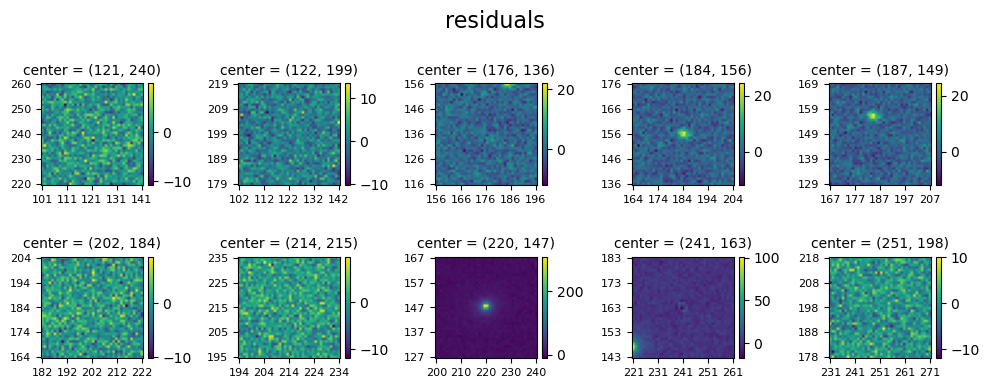

In [19]:
choice_img = 0
VALUE = 300
outliers = df[df["pixel_value"] > VALUE]
image_ids_with_outliers = outliers["image_id"].unique()
print(image_ids_with_outliers)
CHOICE_IMAGE = image_ids_with_outliers[choice_img]

residuals(DATASET_DIR, IMAGES_DIR, f"{CHOICE_IMAGE:06d}_simu", PLOTS_DIR)

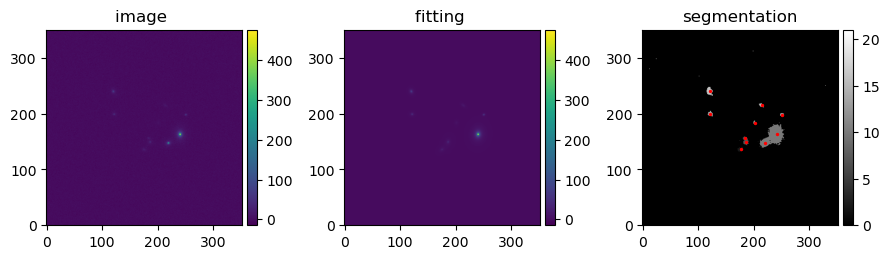

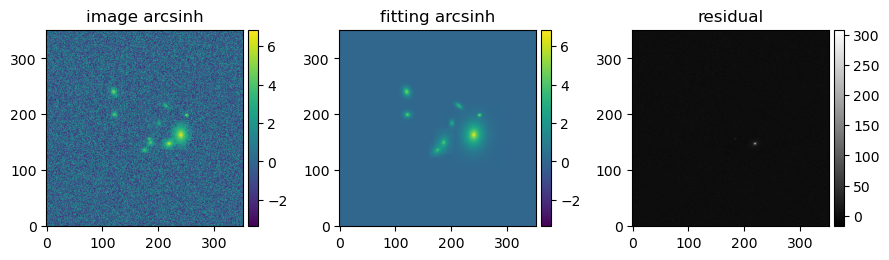

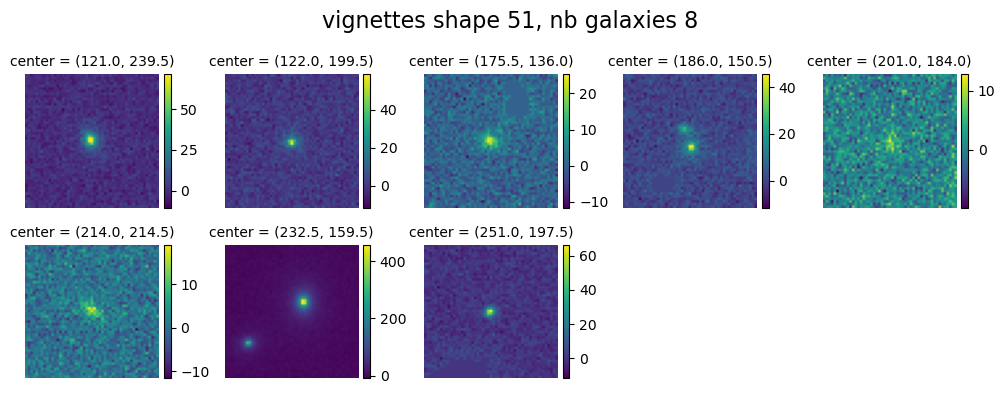

In [20]:
if CHOICE_IMAGE <= 100:
    image_fitting(DATASET_DIR, IMAGES_DIR, f"{CHOICE_IMAGE:06d}_simu", PLOTS_DIR)
    image_fitting(DATASET_DIR, IMAGES_DIR, f"{CHOICE_IMAGE:06d}_simu", PLOTS_DIR, transformed=True)
    # residuals(DATASET_DIR, IMAGES_DIR, f"{CHOICE_IMAGE:06d}_simu", PLOTS_DIR)
    vignettes(CATALOG_DIR, IMAGES_DIR, f"{CHOICE_IMAGE:06d}_simu", PLOTS_DIR)

# results by params

In [21]:
# bin_width = 0.5
# bin_mag = interval_range(start=20, end=24 + bin_width, freq=bin_width, closed="left")
# true_gal_slice["mag_bin"] = cut(true_gal_slice["mag"], bins=bin_mag)

# result_e(PLOTS_DIR, pred_gal_slice, true_gal_slice, err=0)

In [22]:
# case_result_param(PLOTS_DIR, pred_gal_slice, true_gal_slice, PIXEL_SCALE)

# sersic

In [23]:
# from plots import x_n_seric

# MIN_SERSIC = 0.2
# MAX_SERSIC = 6.5
# MU_X = -2.6
# SIGMA_X = 1.1

# x_n_seric(MIN_SERSIC, MAX_SERSIC, MU_X, SIGMA_X, PLOTS_DIR)